# 02 · Cost of drinking (Q2)
**Question:** Has drinking become less affordable for young people in Ireland, and could cost explain why pubs are closing?

**Data** (produced by `src/clean.py`):
- `cpi.csv`: CSO Consumer Price Index, *Alcoholic beverages and tobacco*, monthly, Nov 2019 – Dec 2025 (base Dec 2023 = 100)
- `min_wage_monthly.csv`: national minimum wage for every month
- `pubs_national.csv`: pub numbers by year (from Chunk 3)

**Why the minimum wage?** Many young people work part-time or entry-level jobs near the minimum wage, so it's a reasonable benchmark for what a young worker earns. It isn't what every young person earns.

**Sections**
1. How have alcohol prices changed?
2. Prices vs wages on the same scale
3. Affordability: what an hour's work buys
4. Affordability vs pub closures
5. Findings

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

cpi = pd.read_csv(PROCESSED / "cpi.csv")
wage = pd.read_csv(PROCESSED / "min_wage_monthly.csv")
pubs = pd.read_csv(PROCESSED / "pubs_national.csv")

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "font.size": 11,
})
MAIN, HIGHLIGHT, MUTED = "#0f62fe", "#da1e28", "#a8a8a8"

# Keep only the months where both prices and wages exist
df = cpi.merge(wage, on="month", how="inner")
df["date"] = pd.to_datetime(df["month"])
print(f"Overlapping months: {df.month.min()} to {df.month.max()} ({len(df)} months)")
df.head()

Overlapping months: 2019-11 to 2025-12 (74 months)


,month,series,index_value,base,yoy_pct,hourly_rate_eur,date
0,2019-11,Alcoholic beverages and tobacco,84.2,Base Dec 2023=100,NaN,9.8,2019-11-01
1,2019-12,Alcoholic beverages and tobacco,83.8,Base Dec 2023=100,NaN,9.8,2019-12-01
2,2020-01,Alcoholic beverages and tobacco,87.0,Base Dec 2023=100,NaN,9.8,2020-01-01
3,2020-02,Alcoholic beverages and tobacco,86.0,Base Dec 2023=100,NaN,10.1,2020-02-01
4,2020-03,Alcoholic beverages and tobacco,85.5,Base Dec 2023=100,NaN,10.1,2020-03-01


## 1. How have alcohol prices changed?
The CPI is an **index**, not a price in euro. A value of 100 means "the price level in December 2023." 110 means prices are 10% higher than then.

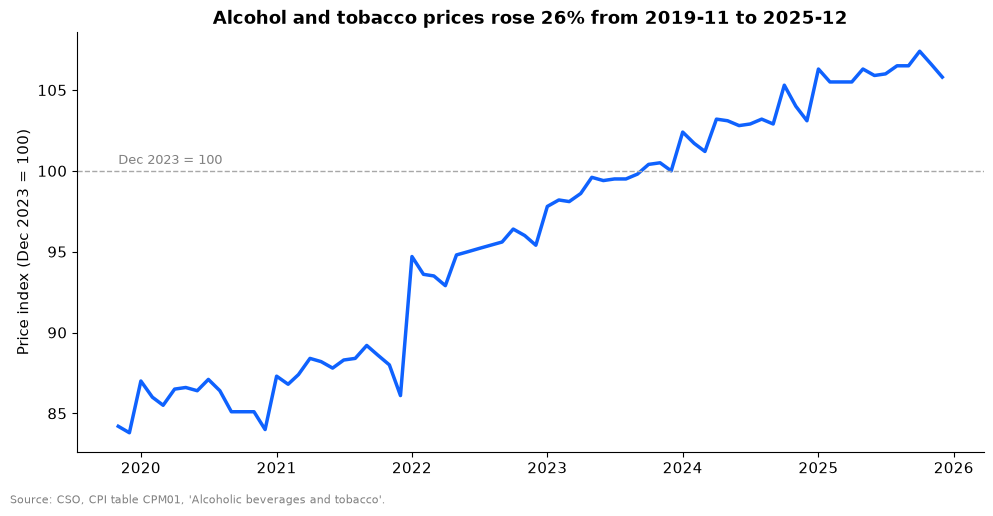

In [2]:
fig, ax = plt.subplots()
ax.plot(df.date, df.index_value, color=MAIN, linewidth=2.5)
ax.axhline(100, color=MUTED, linestyle="--", linewidth=1)
ax.annotate("Dec 2023 = 100", xy=(df.date.iloc[0], 100), xytext=(0, 5),
            textcoords="offset points", fontsize=9, color="grey")

start, end = df.iloc[0], df.iloc[-1]
change = end.index_value / start.index_value - 1
ax.set_title(f"Alcohol and tobacco prices rose {change:.0%} from {start.month} to {end.month}")
ax.set_ylabel("Price index (Dec 2023 = 100)")
fig.text(0.01, -0.02, "Source: CSO, CPI table CPM01, 'Alcoholic beverages and tobacco'.", fontsize=8, color="grey")
fig.tight_layout()
fig.savefig(FIGURES / "02_alcohol_prices.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
# Year-on-year inflation: how much higher prices are than 12 months earlier
yearly = (
    df.assign(year=df.month.str[:4])
      .groupby("year")
      .agg(avg_index=("index_value", "mean"), avg_wage=("hourly_rate_eur", "mean"))
      .round(2)
)
yearly["price_change_pct"] = (yearly.avg_index.pct_change() * 100).round(1)
yearly["wage_change_pct"] = (yearly.avg_wage.pct_change() * 100).round(1)
yearly

,avg_index,avg_wage,price_change_pct,wage_change_pct
year,,,,
2019,84.00,9.80,NaN,NaN
2020,85.90,10.07,2.3,2.8
2021,87.88,10.20,2.3,1.3
2022,94.88,10.50,8.0,2.9
2023,99.28,11.30,4.6,7.6
2024,102.98,12.70,3.7,12.4
2025,106.15,13.50,3.1,6.3


## 2. Prices vs wages on the same scale
Prices are an index and wages are in euro, so they can't go on one chart as they are.
The fix is to **index both to the same starting month: January 2020 = 100**. Then each line shows how much it has grown since then.

In [4]:
BASE = "2020-01"
base = df.loc[df.month == BASE].iloc[0]

df["price_index_2020"] = df.index_value / base.index_value * 100
df["wage_index_2020"] = df.hourly_rate_eur / base.hourly_rate_eur * 100

latest = df.iloc[-1]
print(f"Since {BASE}:")
print(f"  Alcohol & tobacco prices: {latest.price_index_2020 - 100:+.1f}%")
print(f"  Minimum wage:             {latest.wage_index_2020 - 100:+.1f}%")

Since 2020-01:
  Alcohol & tobacco prices: +21.6%
  Minimum wage:             +37.8%


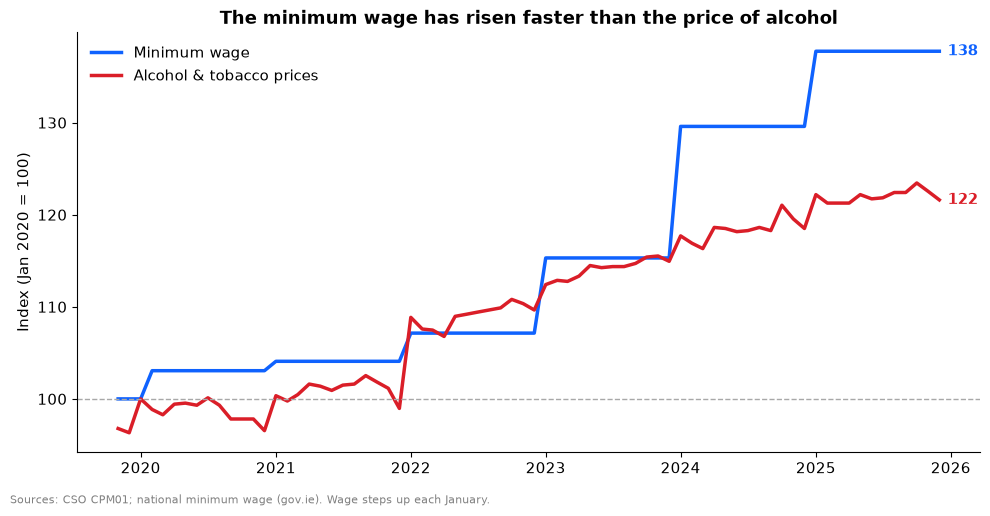

In [5]:
fig, ax = plt.subplots()
ax.plot(df.date, df.wage_index_2020, color=MAIN, linewidth=2.5, label="Minimum wage")
ax.plot(df.date, df.price_index_2020, color=HIGHLIGHT, linewidth=2.5, label="Alcohol & tobacco prices")
for col, colour in [("wage_index_2020", MAIN), ("price_index_2020", HIGHLIGHT)]:
    ax.annotate(f"{latest[col]:.0f}", xy=(latest.date, latest[col]), xytext=(6, 0),
                textcoords="offset points", va="center", color=colour, fontweight="bold")

ax.axhline(100, color=MUTED, linestyle="--", linewidth=1)
ax.set_title("The minimum wage has risen faster than the price of alcohol")
ax.set_ylabel("Index (Jan 2020 = 100)")
ax.legend(frameon=False, loc="upper left")
fig.text(0.01, -0.02, "Sources: CSO CPM01; national minimum wage (gov.ie). Wage steps up each January.", fontsize=8, color="grey")
fig.tight_layout()
fig.savefig(FIGURES / "02_prices_vs_wages.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Affordability: what an hour's work buys
**Affordability index = wage index ÷ price index × 100.**
- Above 100: an hour at minimum wage buys *more* alcohol than in January 2020.
- Below 100: it buys *less*.

This is the metric no single dataset gives you. It comes from combining the two.

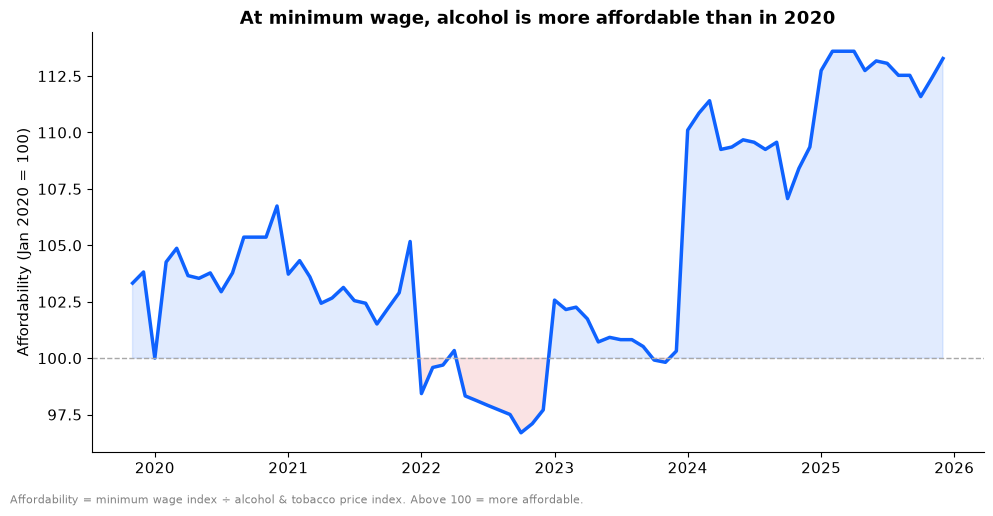

Least affordable month: 2022-10 (96.7)
Latest (2025-12): 113.3


In [6]:
df["affordability"] = df.wage_index_2020 / df.price_index_2020 * 100

fig, ax = plt.subplots()
ax.plot(df.date, df.affordability, color=MAIN, linewidth=2.5)
ax.axhline(100, color=MUTED, linestyle="--", linewidth=1)
ax.fill_between(df.date, 100, df.affordability, where=df.affordability >= 100,
                color=MAIN, alpha=0.12, interpolate=True)
ax.fill_between(df.date, 100, df.affordability, where=df.affordability < 100,
                color=HIGHLIGHT, alpha=0.12, interpolate=True)

ax.set_title("At minimum wage, alcohol is more affordable than in 2020")
ax.set_ylabel("Affordability (Jan 2020 = 100)")
fig.text(0.01, -0.02, "Affordability = minimum wage index ÷ alcohol & tobacco price index. Above 100 = more affordable.",
         fontsize=8, color="grey")
fig.tight_layout()
fig.savefig(FIGURES / "02_affordability.png", dpi=150, bbox_inches="tight")
plt.show()

low = df.loc[df.affordability.idxmin()]
print(f"Least affordable month: {low.month} ({low.affordability:.1f})")
print(f"Latest ({latest.month}): {df.affordability.iloc[-1]:.1f}")

## 4. Affordability vs pub closures
If cost were the main reason pubs are closing, we'd expect closures to speed up as drinking became *less* affordable.
Pub numbers are yearly, so affordability is averaged by year here.

⚠️ This is only six data points, so it's a sense-check, not a statistical test.

In [7]:
yearly_aff = (
    df.assign(year=df.month.str[:4].astype(int))
      .groupby("year")["affordability"].mean()
      .round(1)
)
compare = pubs.set_index("year")[["pub_licences", "annual_change"]].join(yearly_aff, how="inner")
# 2019 only has two months of price data (Nov-Dec), so it isn't a fair yearly average
compare = compare.loc[2020:]
compare

,pub_licences,annual_change,affordability
year,,,
2020,6890,-247.0,104.1
2021,6788,-102.0,103.1
2022,6680,-108.0,98.3
2023,6563,-117.0,101.0
2024,6498,-65.0,109.5
2025,6412,-86.0,112.9


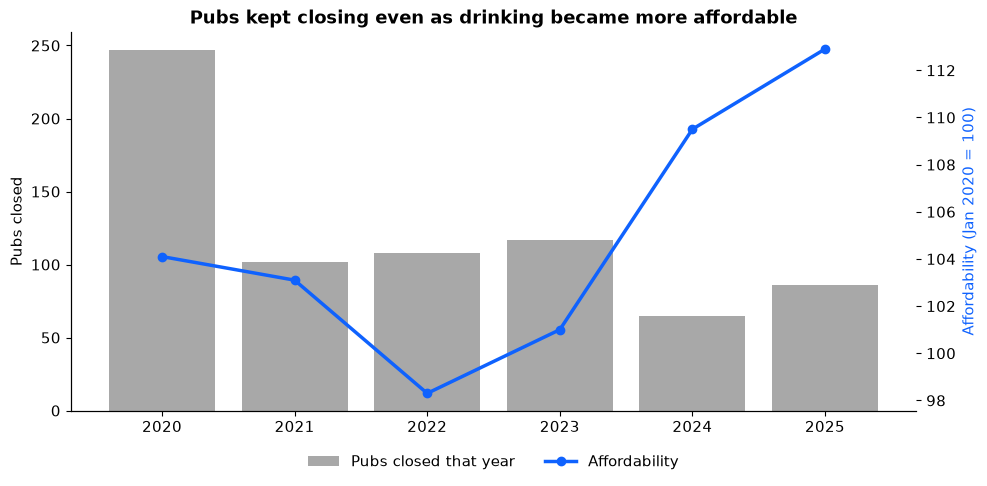

In [8]:
fig, ax1 = plt.subplots()
ax1.bar(compare.index, -compare.annual_change, color=MUTED, label="Pubs closed that year")
ax1.set_ylabel("Pubs closed")
ax1.set_xticks(compare.index)

ax2 = ax1.twinx()
ax2.plot(compare.index, compare.affordability, color=MAIN, linewidth=2.5, marker="o", label="Affordability")
ax2.set_ylabel("Affordability (Jan 2020 = 100)", color=MAIN)
ax2.spines["top"].set_visible(False)

lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(lines, labels, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
ax1.set_title("Pubs kept closing even as drinking became more affordable")
fig.tight_layout()
fig.savefig(FIGURES / "02_affordability_vs_closures.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Findings
_Write these in your own words after looking at the charts. One sentence each._

1. **Prices:** …
2. **Prices vs wages:** …
3. **Affordability:** …
4. **Does cost explain closures?** …

**Caveats**
- The CPI series covers **alcohol *and* tobacco**, and doesn't separate pub prices from off-licence prices. Pub pints may have risen faster than this index.
- The minimum wage isn't everyone's wage, and this ignores **other costs** like rent, which have also risen and leave less money for going out.
- Affordability vs closures is **six yearly points**, which is enough to question a "pubs are closing because drink is too expensive" story, but not enough to prove anything.